# 중고차 매물 데이터 분석

현대·기아 인증중고차와 헤이딜러에서 수집한 매물을 하나의 표로 합쳐,
플랫폼별로 어떤 차가 얼마에 올라와 있는지와 통합 스키마를 만들 때 문제가 될 부분을 본다.

- 데이터: `data/processed/{hyundai,kia,heydealer}/2026-11-23.jsonl` (`scripts/crawl.py`로 수집)
- 엔카는 시험 수집 24건뿐이고 문서상 수집 제외 대상이라 뺐다. 케이카는 아직 수집 결과가 없다.
- 가격 단위는 만원

In [1]:
import matplotlib.pyplot as plt

pd_options = {"display.max_columns": 30, "display.width": 160}
plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#9a9893", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
SOURCE_COLOR = {"hyundai": "#2a78d6", "kia": "#eb6834", "heydealer": "#1baf7a"}
SOURCES = list(SOURCE_COLOR)

## 1. 하나의 표로 합치기

사이트마다 필드 이름과 단위가 달라서 공통 컬럼으로 옮긴다.

| 컬럼 | 현대 | 기아 | 헤이딜러 |
|---|---|---|---|
| price | `price` "2,490만원" | `discountedPrice` 또는 `price` (원) | `price` (만원) |
| new_price | `new_car_price` (원) | 없음 | `factory_price` (만원) |
| model | `vehicle_modelgroup` | `modelCodeName` | `model_part_name` (세대명 포함) |
| my_damage | 보험이력 `내차피해` 건수 | `insuranceRecord.damaged` | `my_car_accident_count` |
| owner_changes | 보험이력 `소유자변경` 건수 | 보험이력 `ownerChange` | `owner_changed_count` |

In [2]:
import json, re
from pathlib import Path
import pandas as pd

DATA = Path("data/processed")
DAY = "2026-11-23"

def read_jsonl(source):
    with open(DATA / source / f"{DAY}.jsonl", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

def num(s):
    if s is None:
        return None
    if isinstance(s, (int, float)):
        return s
    d = re.sub(r"[^\d.]", "", str(s))
    return float(d) if d else None

def count(s):
    if s in (None, "", "없음"):
        return 0 if s == "없음" else None
    m = re.search(r"\d+", str(s))
    return int(m.group()) if m else (1 if "있음" in str(s) else 0)

FUEL = {"GASOLINE": "가솔린", "DIESEL": "디젤", "HYBRID": "하이브리드", "ELECTRIC": "전기", "LPG": "LPG",
        "휘발유": "가솔린", "경유": "디젤"}

def norm_fuel(s):
    if not s:
        return None
    s = FUEL.get(str(s).upper(), FUEL.get(str(s), str(s)))
    if "하이브리드" in s or "HEV" in s.upper(): return "하이브리드"
    if "전기" in s: return "전기"
    if "LPG" in s.upper(): return "LPG"
    if "디젤" in s: return "디젤"
    if "가솔린" in s or "휘발유" in s: return "가솔린"
    return s

def hyundai():
    out = []
    for r in read_jsonl("hyundai"):
        b, mi, ins = r.get("basic_info") or {}, r.get("model_info") or {}, r.get("insurance_summary") or {}
        out.append({
            "source": "hyundai", "id": r["id"],
            "brand": "제네시스" if mi.get("brand_type") == "GHQ" else "현대",
            "model": mi.get("vehicle_modelgroup"), "name": r.get("name"),
            "year": num(b.get("연식")), "first_reg": b.get("최초등록", "").replace(".", "-") or None,
            "mileage": num(b.get("주행거리")), "price": num(r.get("price")),
            "new_price": (num(r.get("new_car_price")) or 0) / 10000 or None,
            "fuel": norm_fuel(b.get("연료")), "body": b.get("차종"),
            "my_damage": count(ins.get("내차피해", b.get("내차피해"))),
            "owner_changes": count(ins.get("소유자변경")),
            "plate": b.get("차량번호"),
        })
    return out

def kia():
    out = []
    for r in read_jsonl("kia"):
        d = r["detail"]; c = d["car"]; ih = r.get("insurance-history") or {}
        disc = (d.get("discount") or {}).get("discountedPrice")
        out.append({
            "source": "kia", "id": r["id"], "brand": "기아",
            "model": c.get("modelCodeName"), "name": c.get("modelName"),
            "year": c.get("modelYear"), "first_reg": c.get("firstRegisteredOn"),
            "mileage": c.get("drivingDistance"), "price": (disc or c.get("price")) / 10000,
            "new_price": None,
            "fuel": norm_fuel(c.get("fuelType")), "body": c.get("modelCategory"),
            "my_damage": (d.get("insuranceRecord") or {}).get("damaged"),
            "owner_changes": count((ih.get("summary") or {}).get("ownerChange")),
            "plate": c.get("plateNumber"),
        })
    return out

def heydealer():
    out = []
    for r in read_jsonl("heydealer"):
        di = r["detail_info"]; ch = di.get("carhistory") or {}
        out.append({
            "source": "heydealer", "id": r["id"], "brand": di.get("brand_name"),
            "model": di.get("model_part_name"), "name": f"{di.get('model_part_name')} {di.get('grade_name')}",
            "year": di.get("year"), "first_reg": (di.get("initial_registration_date") or "")[:10] or None,
            "mileage": di.get("mileage"), "price": r.get("price"),
            "new_price": di.get("factory_price"),
            "fuel": norm_fuel(di.get("fuel_display")), "body": None,
            "my_damage": ch.get("my_car_accident_count"),
            "owner_changes": ch.get("owner_changed_count"),
            "plate": r.get("car_number"),
        })
    return out

cars = pd.DataFrame(hyundai() + kia() + heydealer())
cars["first_reg"] = pd.to_datetime(cars["first_reg"], errors="coerce")

cars["fuel"] = cars["fuel"].replace({"ELECTRICITY": "전기"})
cars["age"] = (pd.Timestamp("2026-11-23") - cars["first_reg"]).dt.days / 365.25
for k, v in pd_options.items():
    pd.set_option(k, v)
cars.groupby("source").size().rename("매물 수").to_frame()

,매물 수
source,
heydealer,3409
hyundai,1724
kia,1095


## 2. 필드 채움률

통합 스키마에서 비는 칸. 0%인 칸은 그 사이트가 아예 주지 않는 정보다.

In [3]:
fill = cars.drop(columns=["id", "age"]).groupby(cars["source"]).agg(lambda s: s.notna().mean()).T[SOURCES]
fill.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

source,hyundai,kia,heydealer
brand,100%,100%,100%
model,100%,100%,100%
name,100%,100%,100%
year,100%,100%,100%
first_reg,100%,100%,100%
mileage,100%,100%,100%
price,100%,100%,100%
new_price,100%,0%,100%
fuel,100%,100%,100%
body,100%,100%,0%


## 3. 플랫폼별 가격·연식·주행거리

현대·기아 인증중고차는 출고 5년 이내 차만 다루고, 헤이딜러는 연식 폭이 넓다.

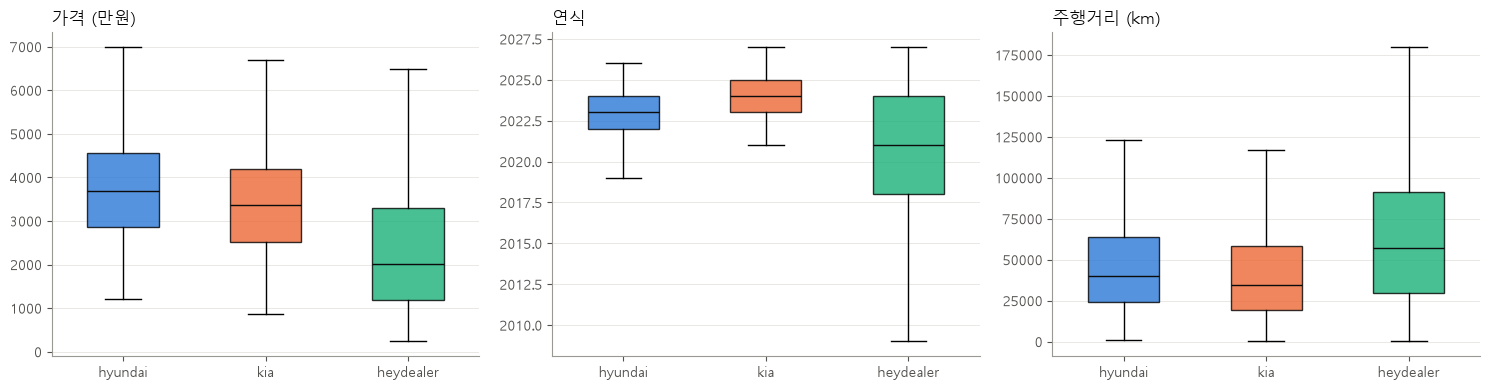

,price,year,mileage
source,,,
hyundai,3690.0,2023.0,39957.0
kia,3373.0,2024.0,34778.0
heydealer,2010.0,2021.0,57104.0


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, label in zip(axes, ["price", "year", "mileage"], ["가격 (만원)", "연식", "주행거리 (km)"]):
    data = [cars.loc[cars["source"] == s, col].dropna() for s in SOURCES]
    bp = ax.boxplot(data, tick_labels=SOURCES, showfliers=False, patch_artist=True, widths=0.5)
    for patch, s in zip(bp["boxes"], SOURCES):
        patch.set_facecolor(SOURCE_COLOR[s])
        patch.set_alpha(0.8)
    for median in bp["medians"]:
        median.set_color("#0b0b0b")
    ax.set_title(label, loc="left")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

cars.groupby("source")[["price", "year", "mileage"]].median().loc[SOURCES].round(0)

## 4. 브랜드와 모델

헤이딜러의 모델명은 세대까지 붙어 있어("디 올 뉴 그랜저 하이브리드(GN7)") 현대·기아의 모델명("그랜저")과 바로 맞지 않는다.
비교를 위해 앞뒤 수식어와 괄호를 떼어 `model_base`를 만든다.

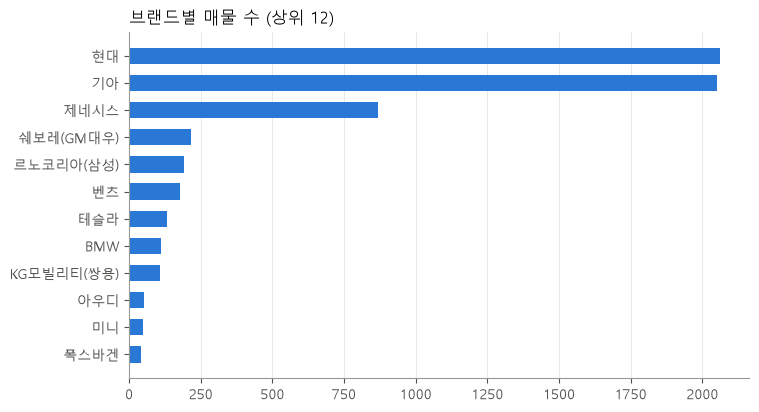

In [5]:
import re

PREFIX = re.compile(r"^(디\s?올\s?뉴|더\s?올\s?뉴|올\s?뉴|더\s?뉴|뉴|신형|디\s?엣지|어메이징\s?뉴|더\s?넥스트|기아|현대|제네시스)\s+")

def model_base(name):
    s = re.sub(r"\s*\(.*?\)", "", name or "").strip()
    while PREFIX.match(s):
        s = PREFIX.sub("", s)
    s = re.sub(r"\s+(FL|PE)$", "", s)
    s = re.sub(r"\s*(하이브리드|HEV)$", "", s)
    return s.strip()

cars["model_base"] = cars["model"].map(model_base)
top_brand = cars["brand"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_brand.index[::-1], top_brand.values[::-1], color="#2a78d6", height=0.6)
ax.set_title("브랜드별 매물 수 (상위 12)", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

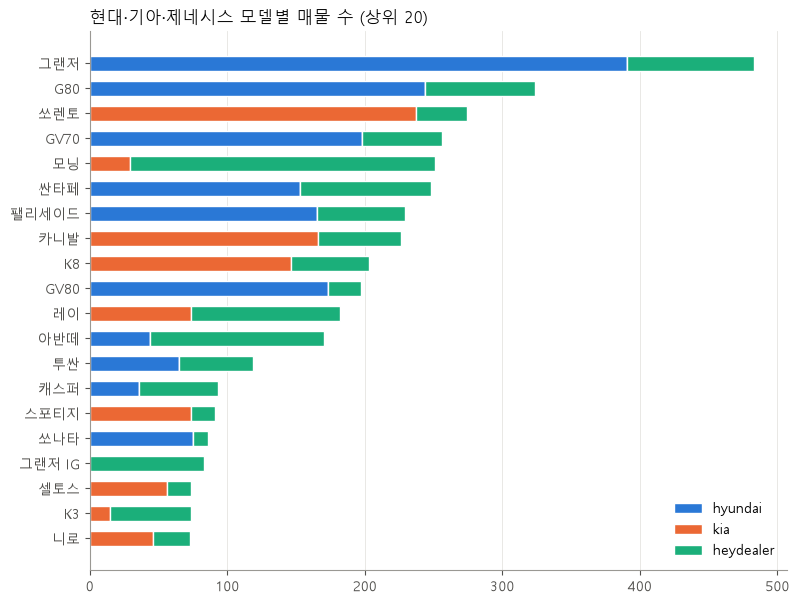

In [6]:
domestic = cars[cars["brand"].isin(["현대", "기아", "제네시스"])]
top_models = (domestic.groupby(["model_base", "source"]).size().unstack(fill_value=0)
              .reindex(columns=SOURCES, fill_value=0))
top_models = top_models.loc[top_models.sum(axis=1).sort_values(ascending=False).index[:20]]

fig, ax = plt.subplots(figsize=(9, 7))
left = None
for s in SOURCES:
    vals = top_models[s].values[::-1]
    ax.barh(top_models.index[::-1], vals, left=left, color=SOURCE_COLOR[s], height=0.6, label=s,
            edgecolor="white", linewidth=1)
    left = vals if left is None else left + vals
ax.set_title("현대·기아·제네시스 모델별 매물 수 (상위 20)", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

## 5. 연료 구성

In [7]:
fuel = pd.crosstab(cars["source"], cars["fuel"], normalize="index").loc[SOURCES]
fuel = fuel[fuel.sum().sort_values(ascending=False).index]
fuel.style.format("{:.1%}")

fuel,가솔린,하이브리드,전기,디젤,LPG,수소,바이퓨얼
source,,,,,,,
hyundai,69.6%,21.5%,8.1%,0.1%,0.7%,0.0%,0.0%
kia,32.1%,39.6%,12.4%,15.0%,0.9%,0.0%,0.0%
heydealer,57.1%,11.9%,11.2%,16.4%,3.0%,0.4%,0.0%


## 6. 감가: 신차가 대비 현재 가격

신차가가 있는 현대·헤이딜러 매물만 본다. 출고 후 경과 연수(최초등록 기준)별 `가격 / 신차가`의 중앙값.

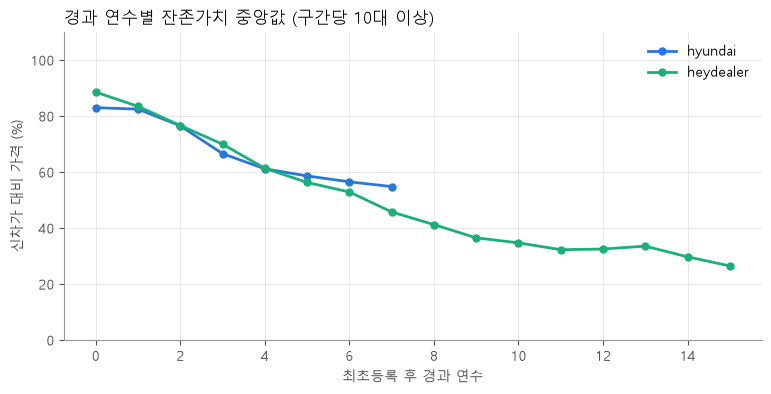

In [8]:
dep = cars.dropna(subset=["new_price", "age"]).query("new_price > 0").copy()
dep["ratio"] = dep["price"] / dep["new_price"]
dep["age_bin"] = dep["age"].clip(upper=15).astype(int)
curve = dep.groupby(["source", "age_bin"])["ratio"].agg(["median", "size"]).reset_index()
curve = curve[curve["size"] >= 10]

fig, ax = plt.subplots(figsize=(9, 4))
for s in ["hyundai", "heydealer"]:
    c = curve[curve["source"] == s]
    ax.plot(c["age_bin"], c["median"] * 100, color=SOURCE_COLOR[s], linewidth=2, marker="o", markersize=5, label=s)
ax.set_xlabel("최초등록 후 경과 연수")
ax.set_ylabel("신차가 대비 가격 (%)")
ax.set_ylim(0, 110)
ax.set_title("경과 연수별 잔존가치 중앙값 (구간당 10대 이상)", loc="left")
ax.legend(frameon=False)
plt.show()

In [9]:
dom = dep[dep["brand"].isin(["현대", "기아", "제네시스"]) & dep["age"].between(2, 4)]
by_model = dom.groupby("model_base")["ratio"].agg(["median", "size"]).query("size >= 15").sort_values("median")
by_model.columns = ["잔존가치 중앙값", "매물 수"]
print("출고 2~4년 차, 현대·기아·제네시스, 모델당 15대 이상")
by_model.style.format({"잔존가치 중앙값": "{:.0%}"})

출고 2~4년 차, 현대·기아·제네시스, 모델당 15대 이상


,잔존가치 중앙값,매물 수
model_base,,
아이오닉 6,55%,43
G90,55%,20
아이오닉 5,61%,39
G80,66%,146
GV80,70%,119
레이 EV,70%,36
팰리세이드,70%,72
그랜저,73%,275
K8,73%,27


## 7. 주행거리와 가격: 같은 모델 안에서

가장 매물이 많은 모델 하나를 골라 연식을 고정하고 주행거리에 따라 가격이 어떻게 달라지는지 본다.

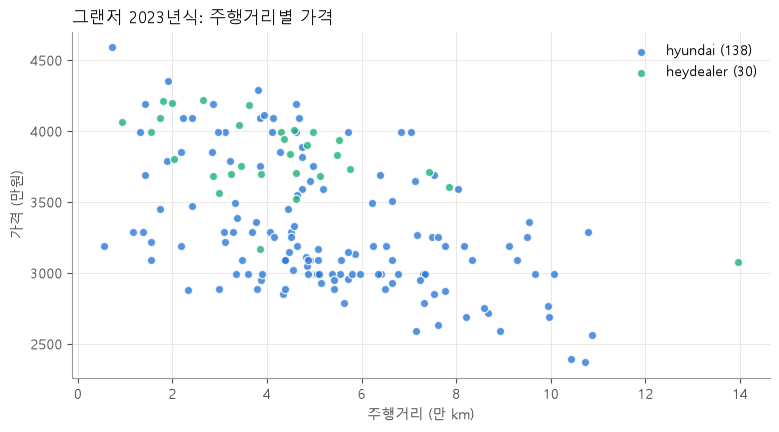

In [10]:
target = top_models.index[0]
sub = cars[(cars["model_base"] == target)].dropna(subset=["mileage", "price"])
year = sub["year"].mode().iloc[0]
sub = sub[sub["year"] == year]

fig, ax = plt.subplots(figsize=(9, 4.5))
for s in SOURCES:
    d = sub[sub["source"] == s]
    if len(d):
        ax.scatter(d["mileage"] / 10000, d["price"], s=36, color=SOURCE_COLOR[s], alpha=0.8,
                   edgecolor="white", linewidth=1, label=f"{s} ({len(d)})")
ax.set_xlabel("주행거리 (만 km)")
ax.set_ylabel("가격 (만원)")
ax.set_title(f"{target} {int(year)}년식: 주행거리별 가격", loc="left")
ax.legend(frameon=False)
plt.show()

## 8. 사고 이력

보험 기록상 내차피해(내 차가 보험으로 수리받은 사고)가 1건 이상인 매물 비율과,
같은 모델·연식 안에서 사고 유무에 따른 가격 차이.

In [11]:
cars["has_damage"] = cars["my_damage"].fillna(0) > 0
print(cars.groupby("source")["has_damage"].mean().loc[SOURCES].map("{:.0%}".format).to_string())

grp = cars.dropna(subset=["price"]).groupby(["source", "model_base", "year"])
paired = grp.filter(lambda g: g["has_damage"].sum() >= 3 and (~g["has_damage"]).sum() >= 3)
gap = (paired.groupby(["source", "model_base", "year", "has_damage"])["price"].median().unstack()
       .rename(columns={False: "무사고", True: "사고"}))
gap["사고차 가격 / 무사고 가격"] = gap["사고"] / gap["무사고"]
print()
print(f"비교 가능한 모델·연식 묶음 {len(gap)}개")
print(gap.groupby("source")["사고차 가격 / 무사고 가격"].median().map("{:.1%}".format).to_string())

source
hyundai      41%
kia          26%
heydealer    52%



비교 가능한 모델·연식 묶음 196개
source
heydealer     96.5%
hyundai      100.0%
kia           98.0%


## 9. 플랫폼 간 중복 매물

차량번호가 같은 매물이 여러 플랫폼에 올라와 있는지 확인한다.

In [12]:
plates = cars.dropna(subset=["plate"])
dup = plates[plates["plate"].duplicated(keep=False)]
print(f"차량번호가 있는 매물 {len(plates):,}건 중 플랫폼 간 중복 {dup['plate'].nunique()}대")

차량번호가 있는 매물 6,228건 중 플랫폼 간 중복 0대


## 10. 정리: 통합 스키마에서 손볼 것

- **신차가**: 기아 인증중고차는 신차가를 주지 않는다. 감가나 "신차 대비 얼마나 싼가"를 쓰려면 제원·가격 DB로 메워야 한다.
- **차종(세단/SUV)**: 헤이딜러는 차종 필드가 없다. 모델명으로 대응표를 만들어야 한다.
- **모델명**: 현대·기아는 모델 그룹("그랜저"), 헤이딜러는 세대명("디 올 뉴 그랜저 하이브리드(GN7)")이라 모델·세대 기준표가 필요하다.
  하이브리드 여부는 모델명이 아니라 연료 컬럼으로 구분해야 한다.
- **연식 범위**: 현대·기아 인증중고차는 출고 5년 이내 차만 있다. 오래된 저가 차는 헤이딜러에만 있어서, 예산이 낮은 사용자에게는 헤이딜러 매물만 나온다.
- **사고 정의**: 현대는 보험 내차피해 건수, 기아는 `damaged`, 헤이딜러는 보험 사고 건수와 별도로 성능점검 요약(완전무사고 등)도 준다. "무사고"의 기준을 하나로 정해야 한다.